# Deep Neural Network for Real Estate Transaction Price Prediction

## 1. Introduction

This notebook explores the use of a feedforward deep neural networks in predicting residential real estate transaction prices.

Building on the data preparation, exploratory analysis, and classical machine learning experiments presented in the previous notebooks, this stage investigates whether a neural network can capture nonlinear relationships between property characteristics, transaction timing, and transaction prices.

The modelling process includes:

- Establishing a baseline architecture and training procedure.
- Investigating model architecture, learning rate, dropout, and weight decay.
- Comparing predictions trained on standardized original transaction prices and logarithmically transformed prices.
- Evaluating generalization using chronological validation and test sets.

A time-based evaluation strategy is used to assess how well the models predict transactions from later periods, rather than relying on a random train-test split.

The objective is not only to assess predictive performance, but also to understand the modelling decisions, optimization process, and limitations of neural networks when applied to real-world real estate data.

## 2. Imports and Configuration

This section imports the required libraries.

PyTorch is used to define and train the neural network, while scikit-learn provides the preprocessing tools used to standardize the input features and target variable.

Random seeds are also used to check and improve the reproducibility of the experiments. Since neural network training involves random parameter initialization, data shuffling, and dropout, fixing the seeds helps make results more consistent across repeated executions.

Reproducibility does not guarantee identical results across every hardware configuration or software environment, but it provides a controlled starting point for experimentation.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility and utilities
import random
import copy

In [2]:
# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the same seed for CUDA, if available
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

## 3. Data Preparation

The dataset used in this notebook is the prepared dataset produced in Notebook 01.

At this stage, the objective is to prepare the relevant features and the target variable for neural network modelling. The original data-cleaning and exploratory steps are not repeated.

In [3]:
# Load prepared dataset
modeling_df = pd.read_parquet("../data/modeling_data.parquet")

# Inspect dataset dimensions
print(f"Dataset shape: {modeling_df.shape}")

# Display the first rows
modeling_df.head()

Dataset shape: (86085, 13)


,municipal_district,number_of_facades,zone_price_eur_per_m2,main_area_m2,auxiliary_area_m2,construction_year,floor,objective_value_proxy,is_apartment,within_appa,contract_year,contract_month,transaction_price_eur
0,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,1,900.0,84.67,13.0,1992.0,3,76203.0,1,1,2017,9,49155.75
1,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,2,900.0,84.50,0.0,1998.0,1,76050.0,1,1,2017,11,60000.00
2,ΑΓΙΑΣ ΒΑΡΒΑΡΑΣ,2,900.0,150.59,0.0,2003.0,3,135531.0,1,1,2017,12,135000.00
3,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,0,1700.0,104.50,0.0,2010.0,4,177650.0,1,1,2017,3,231618.12
4,ΑΓΙΑΣ ΠΑΡΑΣΚΕΥΗΣ,1,1250.0,70.81,0.0,2004.0,1,88512.5,1,1,2017,3,107322.77


In [4]:
# Define input features
feature_columns = [
    "number_of_facades",
    "zone_price_eur_per_m2",
    "main_area_m2",
    "auxiliary_area_m2",
    "construction_year",
    "floor",
    "is_apartment",
    "within_appa",
    "contract_year",
    "contract_month",
]

# Define target variable
target_column = "transaction_price_eur"

# Separate binary and continuous features
binary_feature_columns = [
    "is_apartment",
    "within_appa",
]

continuous_feature_columns = [
    col for col in feature_columns
    if col not in binary_feature_columns
]

## 4. Temporal Splitting and Extreme Value Filtering

The dataset is divided chronologically to simulate the task of predicting future real estate transactions using historical data.

The four periods are:

- **Training:** 2017–2023
- **Validation:** 2024
- **Test:** 2025
- **Forward-looking evaluation:** 2026

This approach ensures that the model is trained exclusively on transactions that occurred before the periods used for validation and testing.

The 2026 evaluation is treated separately because the available data covers only part of the year (up to August).

Following the approach adopted in the classical machine learning notebook, we also apply a fixed 99th-percentile transaction-price cutoff of **€725,532.81** to all four datasets.

The upper tail contains a relatively small number of transactions with prices substantially higher than the central distribution. Although these observations may represent genuine high-value properties, their extreme values can disproportionately influence error-based metrics and the training process.

For this initial modelling exercise, we therefore focus on the central 99% of transactions. This provides a more interpretable evaluation of typical transaction prices and maintains consistency with the previous modelling stage.

Importantly, the cutoff was calculated using the complete dataset to remain consistent with the classical machine learning analysis. This is a methodological limitation, since the threshold incorporates information from periods beyond the training set.

In [5]:
# Chronological split

train_df = modeling_df[
    modeling_df["contract_year"].between(2017, 2023)
].copy()

val_df = modeling_df[
    modeling_df["contract_year"] == 2024
].copy()

test_df = modeling_df[
    modeling_df["contract_year"] == 2025
].copy()

df_2026 = modeling_df[
    modeling_df["contract_year"] == 2026
].copy()

In [6]:
# Apply the agreed P99 transaction-price cutoff

p99_cutoff = modeling_df[target_column].quantile(0.99)

train_df_p99 = train_df[
    train_df[target_column] <= p99_cutoff
].copy()

val_df_p99 = val_df[
    val_df[target_column] <= p99_cutoff
].copy()

test_df_p99 = test_df[
    test_df[target_column] <= p99_cutoff
].copy()

df_2026_p99 = df_2026[
    df_2026[target_column] <= p99_cutoff
].copy()

In [7]:
print("Original split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("2026:", len(df_2026))

print("\nFiltered split sizes:")
print("Train:", len(train_df_p99))
print("Validation:", len(val_df_p99))
print("Test:", len(test_df_p99))
print("2026:", len(df_2026_p99))

print("\nExcluded transactions:")
print(
    "Total:",
    len(modeling_df) -
    (
        len(train_df_p99) +
        len(val_df_p99) +
        len(test_df_p99) +
        len(df_2026_p99)
    )
)

Original split sizes:
Train: 52639
Validation: 13749
Test: 13084
2026: 6613

Filtered split sizes:
Train: 52177
Validation: 13597
Test: 12931
2026: 6519

Excluded transactions:
Total: 861


## 5. Feature and Target Scaling

Neural networks are generally easier to train when continuous input features are on comparable numerical scales.

For this reason, we use `StandardScaler` to standardize the continuous input features and the transaction-price target.

Standardization transforms each variable according to:

$$
z = \frac{x-\mu}{\sigma}
$$

where:

- $x$ is the original value,
- $\mu$ is the mean calculated from the training data,
- $\sigma$ is the corresponding standard deviation.

The scalers are fitted exclusively on the training set. The resulting transformations are then applied to the validation, test, and 2026 datasets without refitting.

This prevents information from the evaluation periods from influencing the scaling parameters.

Binary features are kept in their original 0/1 representation, since they already have a straightforward numerical interpretation.

In [8]:
# Separate input features and target variable

X_train = train_df_p99[feature_columns].copy()
y_train = train_df_p99[[target_column]].copy()

X_val = val_df_p99[feature_columns].copy()
y_val = val_df_p99[[target_column]].copy()

X_test = test_df_p99[feature_columns].copy()
y_test = test_df_p99[[target_column]].copy()

X_2026 = df_2026_p99[feature_columns].copy()
y_2026 = df_2026_p99[[target_column]].copy()

In [9]:
# Initialize scalers
X_scaler = StandardScaler()
y_scaler = StandardScaler()

# Create copies so binary features remain unchanged
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()
X_2026_scaled = X_2026.copy()

# Fit input scaler on training continuous features only
X_train_scaled[continuous_feature_columns] = (
    X_scaler.fit_transform(
        X_train[continuous_feature_columns]
    )
)

# Apply the same transformation to other datasets
X_val_scaled[continuous_feature_columns] = (
    X_scaler.transform(
        X_val[continuous_feature_columns]
    )
)

X_test_scaled[continuous_feature_columns] = (
    X_scaler.transform(
        X_test[continuous_feature_columns]
    )
)

X_2026_scaled[continuous_feature_columns] = (
    X_scaler.transform(
        X_2026[continuous_feature_columns]
    )
)

# Standardize target using training statistics
y_train_scaled = y_scaler.fit_transform(y_train)
y_val_scaled = y_scaler.transform(y_val)
y_test_scaled = y_scaler.transform(y_test)
y_2026_scaled = y_scaler.transform(y_2026)

## 6. Converting Data into PyTorch Tensors

PyTorch uses tensors as its primary data structure for numerical computation and neural network training.

Although our features and target variables are currently stored in pandas DataFrames and NumPy arrays, they must be converted into PyTorch tensors before being passed to the neural network.

We convert the data to `float32`, which is commonly used in deep learning because it provides a good balance between computational efficiency and numerical precision.

The input features have a shape of `(number of observations, number of features)`, while the target has a shape of `(number of observations, 1)`.

Keeping the target as a two-dimensional column is important because the neural network will produce one prediction per observation, with the same shape.

In [10]:
# Convert input features and targets into PyTorch tensors

X_train_tensor = torch.tensor(
    X_train_scaled.to_numpy(dtype=np.float32)
)
y_train_tensor = torch.tensor(
    y_train_scaled, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled.to_numpy(dtype=np.float32)
)
y_val_tensor = torch.tensor(
    y_val_scaled, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled.to_numpy(dtype=np.float32)
)
y_test_tensor = torch.tensor(
    y_test_scaled, dtype=torch.float32
)

X_2026_tensor = torch.tensor(
    X_2026_scaled.to_numpy(dtype=np.float32)
)
y_2026_tensor = torch.tensor(
    y_2026_scaled, dtype=torch.float32
)

In [11]:
print("Training:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Test:", X_test_tensor.shape, y_test_tensor.shape)
print("2026:", X_2026_tensor.shape, y_2026_tensor.shape)

Training: torch.Size([52177, 10]) torch.Size([52177, 1])
Validation: torch.Size([13597, 10]) torch.Size([13597, 1])
Test: torch.Size([12931, 10]) torch.Size([12931, 1])
2026: torch.Size([6519, 10]) torch.Size([6519, 1])


In [12]:
print("Input tensor dtype:", X_train_tensor.dtype)
print("Target tensor dtype:", y_train_tensor.dtype)

print("\nTraining target mean:", y_train_tensor.mean().item())
print("Training target std:", y_train_tensor.std(unbiased=False).item())

print("\nBinary feature values after scaling:")
print(
    X_train_scaled[binary_feature_columns]
    .apply(pd.Series.value_counts)
    .fillna(0)
    .astype(int)
)

Input tensor dtype: torch.float32
Target tensor dtype: torch.float32

Training target mean: 0.0
Training target std: 1.0

Binary feature values after scaling:
   is_apartment  within_appa
1         45495        47500
0          6682         4677


## 7. Creating the Dataset and DataLoader

Training a neural network on the entire dataset at once is not always practical. Instead, we divide the training data into smaller groups called *batches*.

PyTorch provides two useful utilities for this purpose:

- **TensorDataset:** combines the input features and corresponding target values into a dataset. Each observation remains paired with its correct target.
- **DataLoader:** retrieves observations from the dataset in batches and can shuffle their order between epochs.

We use a batch size of 256, meaning that the model processes up to 256 transactions before updating its parameters.

The training data is shuffled at the beginning of each epoch to reduce dependence on the original observation order.

Validation, test, and forward-looking datasets will not be shuffled or used for parameter updates.

In [13]:
# Define batch size
BATCH_SIZE = 256

# Combine input features and targets
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [14]:
# Inspect the first batch
X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Target batch shape:", y_batch.shape)

print("\nNumber of batches per epoch:", len(train_loader))

Input batch shape: torch.Size([256, 10])
Target batch shape: torch.Size([256, 1])

Number of batches per epoch: 204


## 8. Neural Network Architecture

We use PyTorch's `nn.Module` base class to define our neural network.

A neural network consists of layers that transform input data through a sequence of mathematical operations. Each layer contains trainable parameters, which are adjusted during training to minimize the prediction error.

Our model is a **feedforward neural network**, meaning that information flows from the input layer through the hidden layers to the output layer.

We use fully connected (`nn.Linear`) layers, ReLU activation functions, and dropout regularization.

The architecture is designed to be flexible, allowing us to experiment with different numbers of hidden layers and neurons while keeping the same model implementation.

In [15]:

class FlexibleRealEstateNet(nn.Module):
    def __init__(
        self,
        input_size=10,
        hidden_sizes=(32, 16),
        dropout_p=0.1
    ):
        super().__init__()

        # Create hidden layers dynamically
        self.hidden_layers = nn.ModuleList()

        previous_size = input_size

        for hidden_size in hidden_sizes:
            self.hidden_layers.append(
                nn.Linear(previous_size, hidden_size)
            )
            previous_size = hidden_size

        # Create one dropout layer for each hidden layer
        self.dropouts = nn.ModuleList([
            nn.Dropout(p=dropout_p)
            for _ in hidden_sizes
        ])

        # Final output layer: one predicted price
        self.output = nn.Linear(previous_size, 1)

    def forward(self, x):

        for layer, dropout in zip(
            self.hidden_layers,
            self.dropouts
        ):
            x = torch.relu(layer(x))
            x = dropout(x)

        return self.output(x)

In [16]:
model = FlexibleRealEstateNet(
    input_size=10,
    hidden_sizes=(32, 16),
    dropout_p=0.1
)

print(model)

FlexibleRealEstateNet(
  (hidden_layers): ModuleList(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): Linear(in_features=32, out_features=16, bias=True)
  )
  (dropouts): ModuleList(
    (0-1): 2 x Dropout(p=0.1, inplace=False)
  )
  (output): Linear(in_features=16, out_features=1, bias=True)
)


In [17]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Trainable parameters: {total_parameters:,}")

Trainable parameters: 897


## 9. Loss Function and Optimizer

Training a neural network involves two central components:

- A **loss function**, which measures how far the model's predictions are from the actual target values.
- An **optimizer**, which updates the model's trainable parameters to reduce that loss.

For this regression problem, we use Mean Squared Error (MSE) as the loss function.

MSE calculates the average squared difference between predicted and actual standardized transaction prices:

$$
\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

Squaring the errors penalizes larger deviations more heavily than smaller ones.

The model is trained to minimize this loss through backpropagation and gradient-based optimization.

In [18]:
loss_function = nn.MSELoss()

### 9.1 Optimizer

We use the AdamW optimizer to update the neural network's parameters.

AdamW is an adaptive gradient-based optimization algorithm. It uses estimates of the first and second moments of the gradients to adjust the size of parameter updates.

It also supports weight decay, a regularization technique that discourages unnecessarily large weights.

For our initial configuration, we use:

- Learning rate: 0.003
- Weight decay: 0.0

The learning rate controls the magnitude of parameter updates, while weight decay controls the strength of the regularization penalty.

These values are used as the starting configuration for our experiments and are not assumed to be universally optimal.

In [19]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.003,
    weight_decay=0.0
)

## 10. Training and Evaluation Functions

We define reusable functions for training and evaluating the neural network.

The training function processes the training dataset batch by batch. For each batch, it generates predictions, calculates the loss, computes gradients through backpropagation, and updates the model parameters using the optimizer.

After processing all batches, the function returns the weighted average training loss for the epoch.

The evaluation function follows a different procedure. It calculates the loss on a complete dataset without performing backpropagation or updating model parameters.

This distinction allows us to monitor training progress while using validation loss to assess how well the model generalizes to unseen observations.

In [20]:
def train_one_epoch(model, train_loader, loss_function, optimizer):

    # Set model to training mode
    model.train()

    total_loss = 0.0
    total_properties = 0

    for X_batch, y_batch in train_loader:

        # Clear gradients from previous iteration
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = loss_function(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate weighted batch loss
        batch_size = X_batch.size(0)

        total_loss += loss.item() * batch_size
        total_properties += batch_size

    # Return weighted average loss for the epoch
    epoch_loss = total_loss / total_properties

    return epoch_loss

Two important differences distinguish evaluation from training:

- `model.eval()` switches the model to evaluation mode, disabling dropout.
- `torch.no_grad()` disables gradient tracking, since no parameter updates are performed.

Because the validation dataset is processed as a whole, its loss is calculated using one fixed set of model parameters. This makes it more suitable for comparing model performance across epochs.

In [21]:
def evaluate(model, X, y, loss_function):

    # Set model to evaluation mode
    model.eval()

    # Disable gradient tracking
    with torch.no_grad():

        # Generate predictions
        predictions = model(X)

        # Calculate loss
        loss = loss_function(predictions, y)

    return loss.item()

## 11. Training Loop and Early Stopping

Training a neural network for too few epochs may result in underfitting, while training for too many epochs can lead to overfitting.

To monitor this, we evaluate the model on the validation dataset after every training epoch.

We use **early stopping** to stop training when validation loss no longer improves.

Our implementation uses:

- **Maximum epochs:** an upper limit on the number of training epochs.
- **Patience:** the number of consecutive epochs without sufficient improvement that we allow before stopping.
- **Minimum improvement (`min_delta`):** the minimum reduction in validation loss required to consider an improvement meaningful.

We also save a copy of the model parameters whenever validation loss improves. At the end of training, we restore the best-performing parameters rather than simply keeping those from the final epoch.

This helps us avoid retaining a model that has continued training after its validation performance has started to deteriorate.

In [22]:

def train_model(
    model,
    train_loader,
    X_val,
    y_val,
    loss_function,
    optimizer,
    max_epochs=100,
    patience=5,
    min_delta=0.0001
):

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_model_state = None
    patience_counter = 0

    for epoch in range(max_epochs):

        # Train for one epoch
        train_loss = train_one_epoch(
            model,
            train_loader,
            loss_function,
            optimizer
        )

        # Evaluate on validation data
        val_loss = evaluate(
            model,
            X_val,
            y_val,
            loss_function
        )

        # Store losses
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Check for sufficient validation improvement
        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss

            # Save a copy of the best model parameters
            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        print(
            f"Epoch {epoch + 1:03d}/{max_epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Validation Loss: {val_loss:.6f}"
        )

        # Early stopping
        if patience_counter >= patience:
            print(
                f"\nEarly stopping at epoch {epoch + 1}."
            )
            break

    # Restore the best model parameters
    model.load_state_dict(best_model_state)

    print(f"Best validation loss: {best_val_loss:.6f}")

    return model, history

In [23]:
# Set seed for reproducibility
torch.manual_seed(SEED)

# Initialize a fresh model
baseline_model = FlexibleRealEstateNet(
    input_size=10,
    hidden_sizes=(32, 16),
    dropout_p=0.1
)

# Initialize optimizer
baseline_optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=0.003,
    weight_decay=0.0
)

# Train the model
baseline_model, baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    X_val=X_val_tensor,
    y_val=y_val_tensor,
    loss_function=loss_function,
    optimizer=baseline_optimizer,
    max_epochs=100,
    patience=5,
    min_delta=0.0001
)

Epoch 001/100 | Train Loss: 0.445544 | Validation Loss: 0.486936
Epoch 002/100 | Train Loss: 0.360418 | Validation Loss: 0.467419
Epoch 003/100 | Train Loss: 0.350151 | Validation Loss: 0.459290
Epoch 004/100 | Train Loss: 0.346533 | Validation Loss: 0.451864
Epoch 005/100 | Train Loss: 0.347108 | Validation Loss: 0.439191
Epoch 006/100 | Train Loss: 0.343764 | Validation Loss: 0.440320
Epoch 007/100 | Train Loss: 0.342996 | Validation Loss: 0.462933
Epoch 008/100 | Train Loss: 0.340136 | Validation Loss: 0.460522
Epoch 009/100 | Train Loss: 0.340653 | Validation Loss: 0.461150
Epoch 010/100 | Train Loss: 0.337436 | Validation Loss: 0.453214

Early stopping at epoch 10.
Best validation loss: 0.439191


### 11.1 Visualizing the Training Process

The training and validation loss curves help us understand how the model learns over time.

- Training loss measures how well the model fits the training data.
- Validation loss measures how well it performs on data that was not used to update its weights.

Ideally, both losses decrease. However, if training loss continues to decrease while validation loss stops improving or begins increasing, this can indicate overfitting.

The model's final weights are restored to those from the epoch with the lowest validation loss.

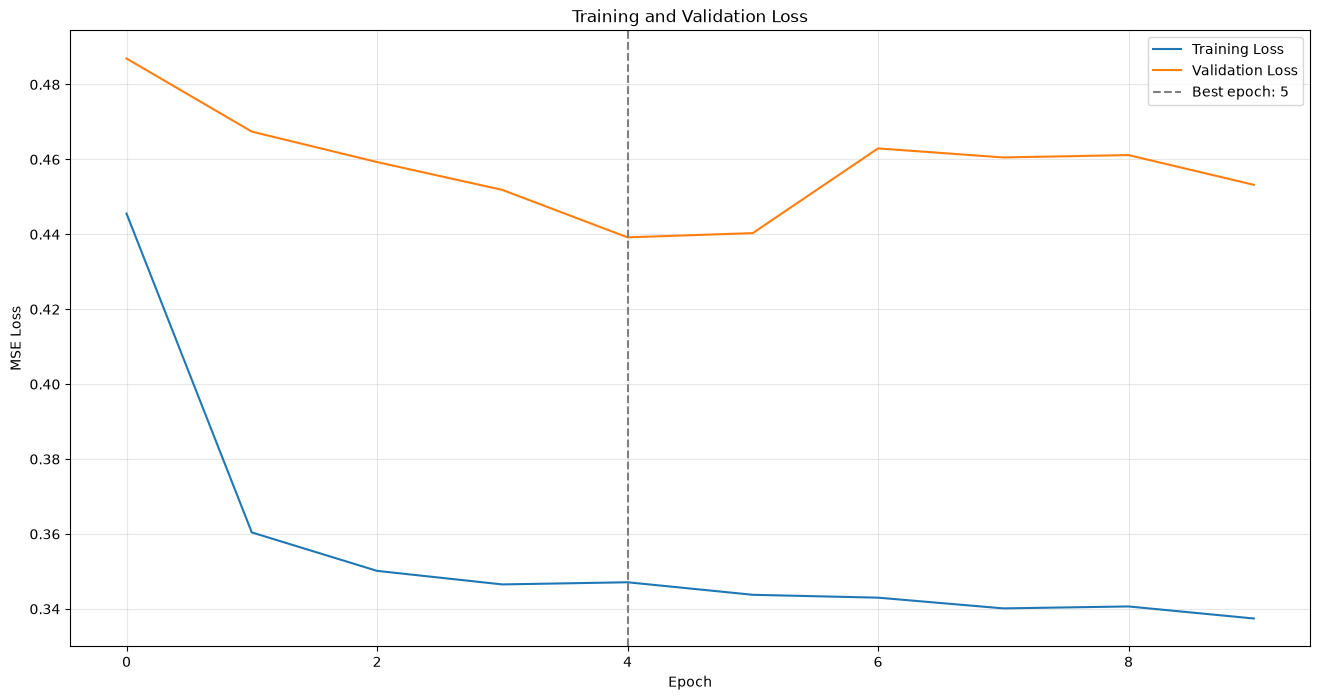

In [24]:
plt.figure(figsize=(16, 8))

plt.plot(
    baseline_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history["val_loss"],
    label="Validation Loss"
)

best_epoch = np.argmin(baseline_history["val_loss"]) + 1

plt.axvline(
    best_epoch - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 12. Regularization - Experiment design 

We compare the following regularization configurations while keeping the network architecture and other training settings fixed:

| Configuration | Dropout | Weight decay |
|---|---:|---:|
| No regularization | 0.0 | 0 |
| Dropout | 0.1 | 0 |
| Dropout + weight decay | 0.1 | 0.0001 |

Each configuration is trained with three different random seeds. We compare the mean and standard deviation of the best validation MSE across the three runs.

A lower mean validation loss indicates better average performance. A lower standard deviation indicates more consistent results across runs.

In [25]:
def run_experiment(
    hidden_sizes,
    dropout_p,
    learning_rate,
    weight_decay,
    seed,
    max_epochs=100
):
    # Set random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Create a reproducible DataLoader
    generator = torch.Generator()
    generator.manual_seed(seed)

    experiment_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    # Initialize a fresh model
    model = FlexibleRealEstateNet(
        input_size=10,
        hidden_sizes=hidden_sizes,
        dropout_p=dropout_p
    )

    # Initialize a fresh optimizer
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    # Train the model
    model, history = train_model(
        model=model,
        train_loader=experiment_loader,
        X_val=X_val_tensor,
        y_val=y_val_tensor,
        loss_function=loss_function,
        optimizer=optimizer,
        max_epochs=max_epochs,
        patience=5,
        min_delta=0.0001
    )

    # Return the best validation loss
    return min(history["val_loss"])

In [26]:
regularization_configs = {
    "No regularization": {
        "dropout_p": 0.0,
        "weight_decay": 0.0
    },
    "Dropout 0.1": {
        "dropout_p": 0.1,
        "weight_decay": 0.0
    },
    "Dropout 0.1 + Weight Decay": {
        "dropout_p": 0.1,
        "weight_decay": 0.0001
    }
}

seeds = [42, 123, 2024]

regularization_results = []

for config_name, config in regularization_configs.items():

    for seed in seeds:

        best_val_loss = run_experiment(
            hidden_sizes=(32, 16),
            dropout_p=config["dropout_p"],
            learning_rate=0.003,
            weight_decay=config["weight_decay"],
            seed=seed
        )

        regularization_results.append({
            "configuration": config_name,
            "seed": seed,
            "best_val_loss": best_val_loss
        })

regularization_df = pd.DataFrame(regularization_results)

regularization_df

Epoch 001/100 | Train Loss: 0.421328 | Validation Loss: 0.451761
Epoch 002/100 | Train Loss: 0.330838 | Validation Loss: 0.468279
Epoch 003/100 | Train Loss: 0.325817 | Validation Loss: 0.464183
Epoch 004/100 | Train Loss: 0.323446 | Validation Loss: 0.433296
Epoch 005/100 | Train Loss: 0.322421 | Validation Loss: 0.446461
Epoch 006/100 | Train Loss: 0.321278 | Validation Loss: 0.467695
Epoch 007/100 | Train Loss: 0.320515 | Validation Loss: 0.447841
Epoch 008/100 | Train Loss: 0.319384 | Validation Loss: 0.446542
Epoch 009/100 | Train Loss: 0.318965 | Validation Loss: 0.458255

Early stopping at epoch 9.
Best validation loss: 0.433296
Epoch 001/100 | Train Loss: 0.419350 | Validation Loss: 0.460054
Epoch 002/100 | Train Loss: 0.331626 | Validation Loss: 0.463015
Epoch 003/100 | Train Loss: 0.326917 | Validation Loss: 0.441204
Epoch 004/100 | Train Loss: 0.324275 | Validation Loss: 0.445060
Epoch 005/100 | Train Loss: 0.322374 | Validation Loss: 0.436774
Epoch 006/100 | Train Loss: 0.3

,configuration,seed,best_val_loss
0,No regularization,42,0.433296
1,No regularization,123,0.436774
2,No regularization,2024,0.439611
3,Dropout 0.1,42,0.441012
4,Dropout 0.1,123,0.441961
5,Dropout 0.1,2024,0.437090
6,Dropout 0.1 + Weight Decay,42,0.441256
7,Dropout 0.1 + Weight Decay,123,0.439755
8,Dropout 0.1 + Weight Decay,2024,0.437621


In [27]:
regularization_summary = (
    regularization_df
    .groupby("configuration")["best_val_loss"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

regularization_summary

,mean,std
configuration,,
No regularization,0.436560,0.003163
Dropout 0.1 + Weight Decay,0.439544,0.001827
Dropout 0.1,0.440021,0.002582


#### Results and interpretation

The three configurations were evaluated using three random seeds each.

The configuration without regularization achieved the lowest mean validation loss (0.436560). Dropout and weight decay did not improve average validation performance in this experiment.

However, the combination of dropout and weight decay produced the lowest standard deviation (0.001827), suggesting somewhat more consistent results across the three runs.

Overall, these results do not provide evidence that regularization improves this network's validation performance. Therefore, the configuration without dropout and weight decay was retained as the preferred setting for the subsequent architecture experiments.

These conclusions are limited to the tested architecture, hyperparameters and random seeds. They do not establish that regularization is generally harmful or unnecessary.

### 13. Comparing network architectures

The architecture of a neural network determines how many hidden layers it contains and how many neurons are used in each layer. These choices influence the model's capacity to learn complex relationships from the data.

A network with too little capacity may fail to capture important patterns (underfitting), while a more complex network may learn unnecessary details from the training data without improving its ability to generalize.

To investigate the effect of network architecture, we compare five configurations with different widths and depths:

- **Small:** `[16, 8]`
- **Baseline:** `[32, 16]`
- **Wide:** `[64, 32]`
- **Deep:** `[32, 32, 16]`
- **Wide and deep:** `[64, 64, 32]`

All other training settings are kept fixed, including the optimizer, learning rate, dropout and weight decay. Each architecture is trained using three different random seeds.

We compare the mean and standard deviation of the best validation loss to assess both average performance and consistency across runs.

The objective is to understand whether increasing network capacity or depth provides a meaningful improvement in validation performance, rather than assuming that a larger network is necessarily better.

In [28]:
architectures = {
    "Small": (16, 8),
    "Baseline": (32, 16),
    "Wide": (64, 32),
    "Deep": (32, 32, 16),
    "Wide and deep": (64, 64, 32)
}

In [29]:
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

architecture_parameters = []

for name, hidden_sizes in architectures.items():

    model = FlexibleRealEstateNet(
        input_size=10,
        hidden_sizes=hidden_sizes,
        dropout_p=0.0
    )

    architecture_parameters.append({
        "architecture": name,
        "hidden_sizes": hidden_sizes,
        "parameters": count_parameters(model)
    })

architecture_df = pd.DataFrame(architecture_parameters)

architecture_df

,architecture,hidden_sizes,parameters
0,Small,"(16, 8)",321
1,Baseline,"(32, 16)",897
2,Wide,"(64, 32)",2817
3,Deep,"(32, 32, 16)",1953
4,Wide and deep,"(64, 64, 32)",6977


In [30]:
architecture_seeds = [42, 123, 2024]

architecture_results = []

for architecture_name, hidden_sizes in architectures.items():

    for seed in architecture_seeds:

        best_val_loss = run_experiment(
            hidden_sizes=hidden_sizes,
            dropout_p=0.0,
            learning_rate=0.003,
            weight_decay=0.0,
            seed=seed
        )

        architecture_results.append({
            "architecture": architecture_name,
            "hidden_sizes": hidden_sizes,
            "seed": seed,
            "best_val_loss": best_val_loss
        })

architecture_results_df = pd.DataFrame(architecture_results)

architecture_results_df

Epoch 001/100 | Train Loss: 0.449075 | Validation Loss: 0.468367
Epoch 002/100 | Train Loss: 0.339485 | Validation Loss: 0.466588
Epoch 003/100 | Train Loss: 0.332194 | Validation Loss: 0.462672
Epoch 004/100 | Train Loss: 0.328487 | Validation Loss: 0.439708
Epoch 005/100 | Train Loss: 0.327662 | Validation Loss: 0.444894
Epoch 006/100 | Train Loss: 0.326433 | Validation Loss: 0.458984
Epoch 007/100 | Train Loss: 0.325655 | Validation Loss: 0.443167
Epoch 008/100 | Train Loss: 0.324882 | Validation Loss: 0.443020
Epoch 009/100 | Train Loss: 0.324437 | Validation Loss: 0.452028

Early stopping at epoch 9.
Best validation loss: 0.439708
Epoch 001/100 | Train Loss: 0.552007 | Validation Loss: 0.483424
Epoch 002/100 | Train Loss: 0.347382 | Validation Loss: 0.469192
Epoch 003/100 | Train Loss: 0.333779 | Validation Loss: 0.443761
Epoch 004/100 | Train Loss: 0.329302 | Validation Loss: 0.451461
Epoch 005/100 | Train Loss: 0.326186 | Validation Loss: 0.442669
Epoch 006/100 | Train Loss: 0.3

,architecture,hidden_sizes,seed,best_val_loss
0,Small,"(16, 8)",42,0.439708
1,Small,"(16, 8)",123,0.437709
2,Small,"(16, 8)",2024,0.437380
3,Baseline,"(32, 16)",42,0.433296
4,Baseline,"(32, 16)",123,0.436774
5,Baseline,"(32, 16)",2024,0.439611
6,Wide,"(64, 32)",42,0.436442
7,Wide,"(64, 32)",123,0.442068
8,Wide,"(64, 32)",2024,0.436750
9,Deep,"(32, 32, 16)",42,0.434950


In [31]:
architecture_summary = (
    architecture_results_df
    .groupby("architecture")["best_val_loss"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

architecture_summary

,mean,std
architecture,,
Baseline,0.436560,0.003163
Wide and deep,0.437128,0.001088
Small,0.438266,0.001260
Wide,0.438420,0.003163
Deep,0.439274,0.003816


#### Results and interpretation

Five architectures with different widths and depths were compared using three random seeds each.

The baseline architecture `[32, 16]` achieved the lowest mean validation loss (0.436560), followed closely by the larger `[64, 64, 32]` architecture (0.437128).

Increasing network capacity did not consistently improve validation performance. In particular, the deeper `[32, 32, 16]` architecture achieved the highest mean validation loss among the tested configurations.

The results suggest that the original baseline architecture provides a reasonable balance between model complexity and validation performance. However, the differences are relatively small and should be interpreted cautiously given the limited number of random seeds.

The baseline architecture was retained as a practical reference for subsequent experiments.

### 14. Learning-rate experiments

The learning rate is one of the most important hyperparameters in neural network training. It controls the size of the parameter updates performed by the optimizer during gradient descent.

If the learning rate is too small, training may progress very slowly and the model may not reach a good solution within the available number of epochs. If it is too large, updates may overshoot good solutions, potentially making training unstable.

To investigate its effect on our model, we compare four learning rates: `0.0001`, `0.0003`, `0.001`, and `0.003`.

All other training settings are kept fixed so that we can isolate the effect of the learning rate. Each configuration is evaluated using three random seeds, and we compare the mean and standard deviation of the best validation loss.

In [32]:
learning_rates = [0.0001, 0.0003, 0.001, 0.003]

learning_rate_seeds = [42, 123, 2024]

learning_rate_results = []

for lr in learning_rates:

    for seed in learning_rate_seeds:

        best_val_loss = run_experiment(
            hidden_sizes=(32, 16),
            dropout_p=0.0,
            learning_rate=lr,
            weight_decay=0.0,
            seed=seed
        )

        learning_rate_results.append({
            "learning_rate": lr,
            "seed": seed,
            "best_val_loss": best_val_loss
        })

learning_rate_results_df = pd.DataFrame(learning_rate_results)

learning_rate_results_df

Epoch 001/100 | Train Loss: 0.916498 | Validation Loss: 1.037515
Epoch 002/100 | Train Loss: 0.780827 | Validation Loss: 0.842861
Epoch 003/100 | Train Loss: 0.593093 | Validation Loss: 0.645120
Epoch 004/100 | Train Loss: 0.453527 | Validation Loss: 0.553020
Epoch 005/100 | Train Loss: 0.399008 | Validation Loss: 0.527991
Epoch 006/100 | Train Loss: 0.381128 | Validation Loss: 0.516893
Epoch 007/100 | Train Loss: 0.372700 | Validation Loss: 0.510092
Epoch 008/100 | Train Loss: 0.367006 | Validation Loss: 0.505601
Epoch 009/100 | Train Loss: 0.362590 | Validation Loss: 0.500052
Epoch 010/100 | Train Loss: 0.358834 | Validation Loss: 0.495812
Epoch 011/100 | Train Loss: 0.355552 | Validation Loss: 0.493666
Epoch 012/100 | Train Loss: 0.352538 | Validation Loss: 0.486312
Epoch 013/100 | Train Loss: 0.349880 | Validation Loss: 0.485307
Epoch 014/100 | Train Loss: 0.347310 | Validation Loss: 0.480257
Epoch 015/100 | Train Loss: 0.344894 | Validation Loss: 0.478278
Epoch 016/100 | Train Los

,learning_rate,seed,best_val_loss
0,0.0001,42,0.450141
1,0.0001,123,0.452286
2,0.0001,2024,0.447293
3,0.0003,42,0.445057
4,0.0003,123,0.436992
5,0.0003,2024,0.441422
6,0.0010,42,0.446240
7,0.0010,123,0.438626
8,0.0010,2024,0.436751
9,0.0030,42,0.433296


In [33]:
learning_rate_summary = (
    learning_rate_results_df
    .groupby("learning_rate")["best_val_loss"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

learning_rate_summary

,mean,std
learning_rate,,
0.0030,0.436560,0.003163
0.0010,0.440539,0.005025
0.0003,0.441157,0.004039
0.0001,0.449907,0.002505


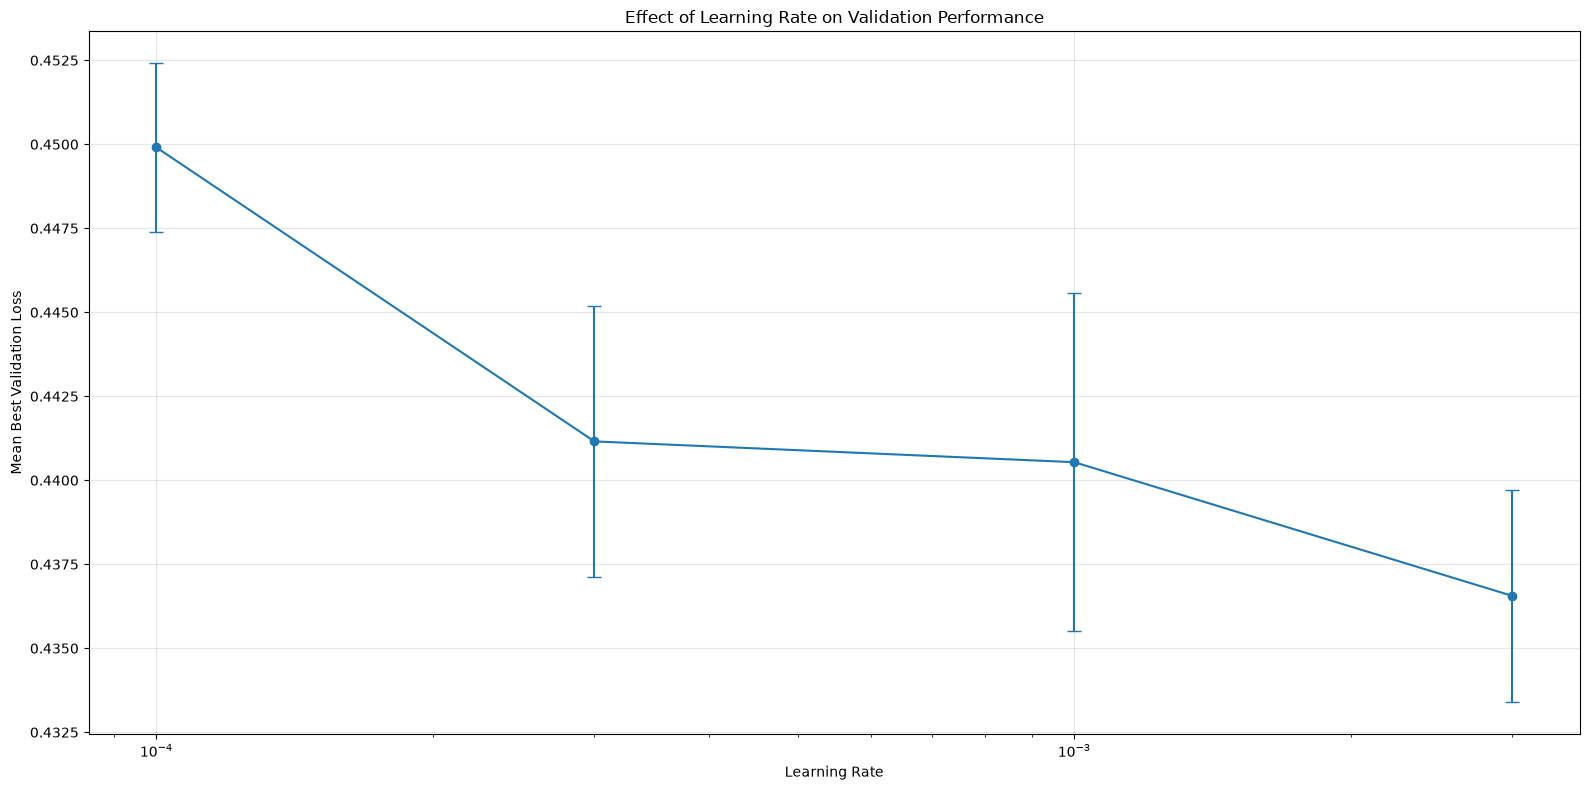

In [34]:
plt.figure(figsize=(16, 8))

plt.errorbar(
    learning_rate_summary.index,
    learning_rate_summary["mean"],
    yerr=learning_rate_summary["std"],
    marker="o",
    capsize=5
)

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Mean Best Validation Loss")
plt.title("Effect of Learning Rate on Validation Performance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Refined learning-rate search

The initial learning-rate experiment showed that `0.003` achieved the lowest mean validation loss among the four tested values.

However, `0.003` was also the highest learning rate in our initial search. This raises a question: could a slightly higher learning rate improve performance further, or have we already reached a good region?

To investigate this, we conduct a narrower search around the initial best result, testing learning rates of `0.002`, `0.003`, `0.004`, and `0.006`.

We also increase the number of random seeds from three to five to obtain a more informative estimate of average performance and variability.

The purpose is not to find a mathematically optimal learning rate, but to check whether our initial choice is reasonable and whether nearby values offer a consistent improvement.

In [35]:
refined_learning_rates = [0.002, 0.003, 0.004, 0.006]
refined_seeds = [42, 123, 2024, 7, 21]

refined_lr_results = []

for lr in refined_learning_rates:

    for seed in refined_seeds:

        best_val_loss = run_experiment(
            hidden_sizes=(32, 16),
            dropout_p=0.0,
            learning_rate=lr,
            weight_decay=0.0,
            seed=seed
        )

        refined_lr_results.append({
            "learning_rate": lr,
            "seed": seed,
            "best_val_loss": best_val_loss
        })

refined_lr_df = pd.DataFrame(refined_lr_results)

refined_lr_df

Epoch 001/100 | Train Loss: 0.450817 | Validation Loss: 0.464022
Epoch 002/100 | Train Loss: 0.334961 | Validation Loss: 0.465625
Epoch 003/100 | Train Loss: 0.327679 | Validation Loss: 0.463612
Epoch 004/100 | Train Loss: 0.323986 | Validation Loss: 0.438010
Epoch 005/100 | Train Loss: 0.322897 | Validation Loss: 0.449979
Epoch 006/100 | Train Loss: 0.321298 | Validation Loss: 0.459331
Epoch 007/100 | Train Loss: 0.320392 | Validation Loss: 0.447397
Epoch 008/100 | Train Loss: 0.319147 | Validation Loss: 0.445817
Epoch 009/100 | Train Loss: 0.319014 | Validation Loss: 0.454390

Early stopping at epoch 9.
Best validation loss: 0.438010
Epoch 001/100 | Train Loss: 0.451909 | Validation Loss: 0.460553
Epoch 002/100 | Train Loss: 0.333954 | Validation Loss: 0.453576
Epoch 003/100 | Train Loss: 0.327598 | Validation Loss: 0.439514
Epoch 004/100 | Train Loss: 0.325203 | Validation Loss: 0.445612
Epoch 005/100 | Train Loss: 0.323314 | Validation Loss: 0.437614
Epoch 006/100 | Train Loss: 0.3

,learning_rate,seed,best_val_loss
0,0.002,42,0.438010
1,0.002,123,0.437614
2,0.002,2024,0.438702
3,0.002,7,0.439249
4,0.002,21,0.436967
5,0.003,42,0.433296
6,0.003,123,0.436774
7,0.003,2024,0.439611
8,0.003,7,0.434318
9,0.003,21,0.440307


In [36]:
refined_lr_summary = (
    refined_lr_df
    .groupby("learning_rate")["best_val_loss"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

refined_lr_summary

,mean,std
learning_rate,,
0.003,0.436861,0.003107
0.004,0.438082,0.003448
0.002,0.438108,0.000896
0.006,0.438822,0.001247


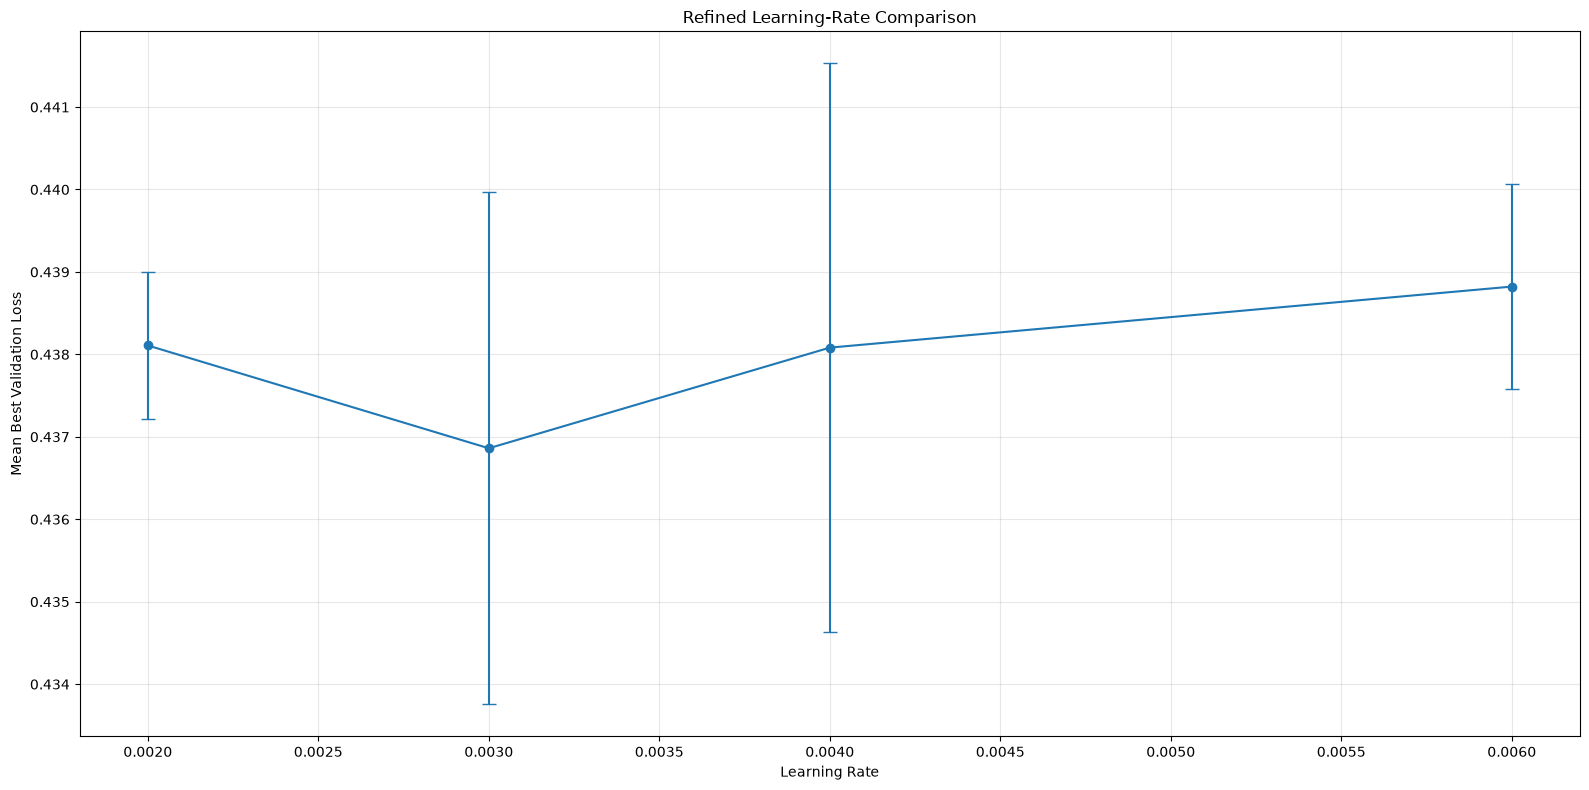

In [37]:
refined_lr_summary = refined_lr_summary.sort_index()

plt.figure(figsize=(16, 8))

plt.errorbar(
    refined_lr_summary.index,
    refined_lr_summary["mean"],
    yerr=refined_lr_summary["std"],
    marker="o",
    capsize=5
)

plt.xlabel("Learning Rate")
plt.ylabel("Mean Best Validation Loss")
plt.title("Refined Learning-Rate Comparison")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Refined learning-rate results and interpretation

The learning rate of `0.003` achieved the lowest mean validation loss (0.436861), followed by `0.004` (0.438082) and `0.002` (0.438108).

Although `0.002` produced the lowest standard deviation, its mean validation performance was slightly worse than that of `0.003`.

Overall, the results support retaining a learning rate of `0.003` for subsequent experiments. However, the differences between the candidate values are relatively small, and the results should not be interpreted as establishing a globally optimal learning rate.

#### Interaction between architecture and learning rate - Methodological Limitation

The architecture and learning-rate experiments were conducted separately. In practice, the effectiveness of a learning rate can depend on the network architecture, meaning that different architectures may perform best under different learning rates.

A more exhaustive hyperparameter search would evaluate multiple architecture–learning-rate combinations jointly. However, this would substantially increase the number of training runs and computational cost.

Given the educational scope and computational constraints of this project, this additional search was not performed. Therefore, the selected architecture and learning rate should be understood as reasonable choices based on separate experiments, rather than a jointly optimized configuration.

## Hyperparameter Experiment Conclusions

The main findings were:

- **Regularization:** Dropout and weight decay did not improve mean validation performance in the tested configurations. The model without regularization achieved the lowest mean validation loss.
- **Architecture:** The baseline architecture `[32, 16]` achieved the lowest mean validation loss among the five architectures evaluated. Increasing network width or depth did not consistently improve performance.
- **Learning rate:** The refined learning-rate experiment supported `0.003` as the best-performing value among the tested candidates.

Based on these experiments, the following configuration was retained as the working baseline:

| Hyperparameter | Selected value |
|---|---|
| Hidden layers | `[32, 16]` |
| Activation function | ReLU |
| Dropout | `0.0` |
| Optimizer | AdamW |
| Learning rate | `0.003` |
| Weight decay | `0.0` |
| Batch size | `256` |
| Early stopping patience | `5` |
| Minimum validation improvement | `0.0001` |

These experiments were conducted separately rather than as a joint search over all possible hyperparameter combinations (which was highlighted as a methodological limitaion earlier). 
The selected configuration represents a practical choice based on the available experiments, not a globally optimized solution.

The results also illustrate that increasing model complexity or adding regularization does not automatically improve generalization. Model choices should be guided by validation performance and the specific characteristics of the dataset.

## 15. Log-Transformed Target

In the previous sections, the neural network was trained to predict transaction prices on their original scale, using a standardized version of the target variable.

However, real-estate transaction prices exhibit a right-skewed distribution, with a relatively small number of high-value transactions extending the upper tail (even after p99 masking).

To investigate whether a different target representation could improve learning, we introduce a logarithmic transformation of the transaction price.

Instead of predicting the original target $y$, the network will learn to predict:

$$
y_{\text{log}} = \ln(y)
$$

The logarithmic transformation compresses large values more strongly than smaller ones, reducing the influence of extreme differences on the target scale.

Importantly, the transformation does not guarantee better results. Both the original-target and log-target models will ultimately be evaluated using prediction errors expressed in euros.

In [38]:
y_train_log = np.log(y_train)
y_val_log = np.log(y_val)

After applying the logarithmic transformation, we standardize the resulting values.

Standardization gives the target a mean of approximately zero and a standard deviation of one, which helps maintain a consistent numerical scale during neural network optimization.

As with the original-target experiment, the scaler is fitted only on the training data. The same transformation parameters are then applied to the validation data.

In [39]:
y_log_scaler = StandardScaler()

y_train_log_scaled = y_log_scaler.fit_transform(y_train_log)
y_val_log_scaled = y_log_scaler.transform(y_val_log)

The transformed and standardized target variables are now converted into PyTorch `float32` tensors just like in the erlier experiments.

In [40]:
y_train_log_tensor = torch.tensor(
    y_train_log_scaled,
    dtype=torch.float32
)

y_val_log_tensor = torch.tensor(
    y_val_log_scaled,
    dtype=torch.float32
)

Before training the model, we inspect the distributions of the original, logarithmically transformed and standardized target variables.

This helps verify that the transformation and standardization have been applied as expected.

In [41]:
print("Original training target:")
print(y_train.describe())

print("\nLog-transformed training target:")
print(y_train_log.describe())

print("\nStandardized log target:")
print(
    "Mean:", y_train_log_scaled.mean(),
    "Standard deviation:", y_train_log_scaled.std()
)

Original training target:
       transaction_price_eur
count           52177.000000
mean           103419.270519
std             88653.434757
min              4357.780000
25%             48000.000000
50%             75000.000000
75%            127000.000000
max            725310.600000

Log-transformed training target:
       transaction_price_eur
count           52177.000000
mean               11.269604
std                 0.732927
min                 8.379718
25%                10.778956
50%                11.225243
75%                11.751942
max                13.494355

Standardized log target:
Mean: 4.009118604131581e-16 Standard deviation: 1.0


### 15.1 Training the Neural Network with the Log-Transformed Target

We now train a neural network using the logarithmically transformed transaction price as its target variable.

To make the comparison with the original-target model meaningful, we keep the input features and training configuration consistent with the corresponding original-target experiment.


| Parameter | Value |
|---|---|
| Hidden layers | `[64, 32]` |
| Activation function | ReLU |
| Dropout | `0` |
| Optimizer | AdamW |
| Learning rate | `0.003` |
| Weight decay | `0` |
| Batch size | `256` |
| Early stopping patience | `5` |
| Minimum validation improvement | `0.0001` |

The only fundamental difference is the target variable: instead of predicting standardized transaction prices, the network now predicts standardized logarithmic transaction prices.

In [42]:
torch.manual_seed(SEED)

log_model = FlexibleRealEstateNet(
    input_size=10,
    hidden_sizes=(64, 32),
    dropout_p=0.0
)

log_optimizer = torch.optim.AdamW(
    log_model.parameters(),
    lr=0.003,
    weight_decay=0.0
)

We train the network using the same input features and training configuration as in the original-target experiment.

However, the training target is now `y_train_log_tensor`, which contains standardized log-transformed transaction prices.

For this reason, we create a separate `DataLoader` (`log_train_loader`) that pairs the training input features with the log-transformed targets. The original `train_loader` still contains the original standardized euro targets and must not be used for this experiment.

Validation performance is monitored using `y_val_log_tensor`, ensuring that both training and validation use the same target representation.

Early stopping is applied using the same settings as before.

In [43]:
log_train_dataset = TensorDataset(
    X_train_tensor,
    y_train_log_tensor
)

log_train_generator = torch.Generator()
log_train_generator.manual_seed(SEED)

log_train_loader = DataLoader(
    log_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=log_train_generator
)

In [44]:
log_model, log_history = train_model(
    model=log_model,
    train_loader=log_train_loader,
    X_val=X_val_tensor,
    y_val=y_val_log_tensor,
    loss_function=loss_function,
    optimizer=log_optimizer,
    max_epochs=100,
    patience=5,
    min_delta=0.0001
)

Epoch 001/100 | Train Loss: 0.322228 | Validation Loss: 0.306944
Epoch 002/100 | Train Loss: 0.271142 | Validation Loss: 0.302403
Epoch 003/100 | Train Loss: 0.266469 | Validation Loss: 0.297567
Epoch 004/100 | Train Loss: 0.265560 | Validation Loss: 0.295072
Epoch 005/100 | Train Loss: 0.263966 | Validation Loss: 0.292474
Epoch 006/100 | Train Loss: 0.262414 | Validation Loss: 0.302045
Epoch 007/100 | Train Loss: 0.260848 | Validation Loss: 0.290200
Epoch 008/100 | Train Loss: 0.260549 | Validation Loss: 0.291362
Epoch 009/100 | Train Loss: 0.259779 | Validation Loss: 0.290346
Epoch 010/100 | Train Loss: 0.259427 | Validation Loss: 0.293924
Epoch 011/100 | Train Loss: 0.259270 | Validation Loss: 0.299177
Epoch 012/100 | Train Loss: 0.258127 | Validation Loss: 0.303381

Early stopping at epoch 12.
Best validation loss: 0.290200


As with the original-target model, we inspect the training and validation loss curves to understand the model's learning behavior.

The losses are now calculated on the standardized logarithmic target scale. Therefore, their numerical values should not be directly compared with the losses obtained when training on the original target.

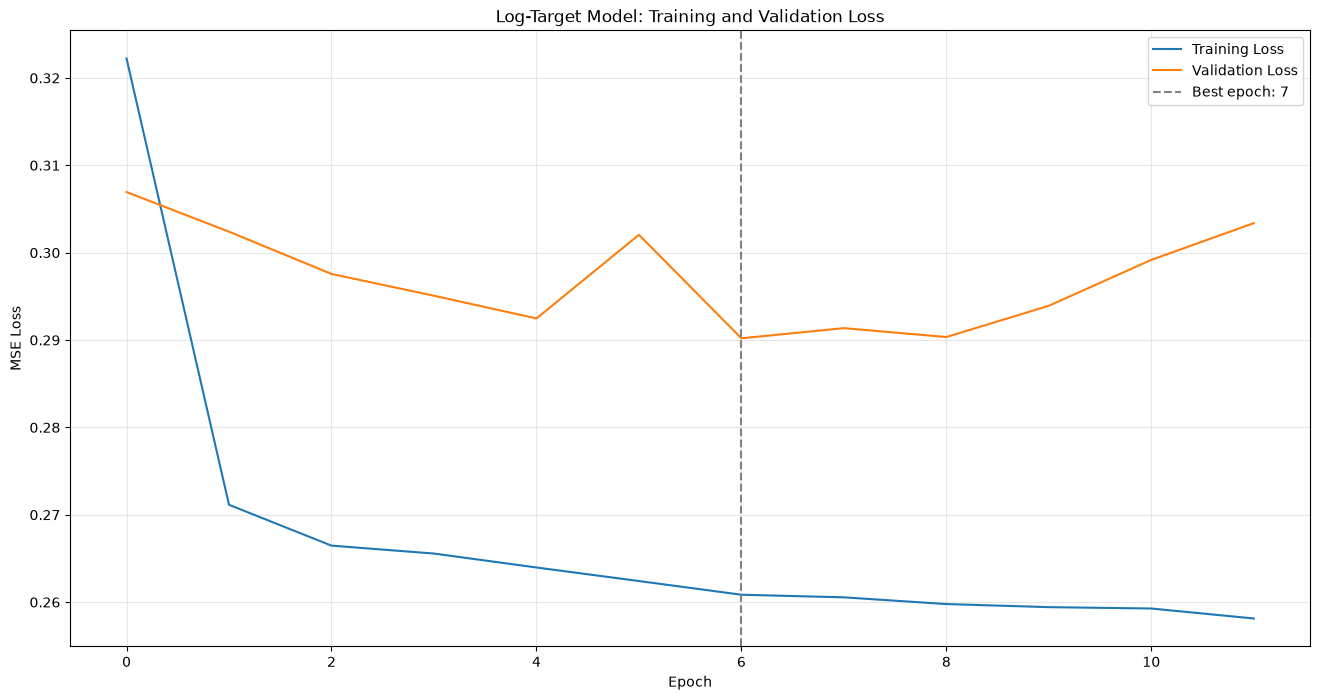

In [45]:
plt.figure(figsize=(16, 8))

plt.plot(
    log_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    log_history["val_loss"],
    label="Validation Loss"
)

best_epoch = np.argmin(log_history["val_loss"]) + 1

plt.axvline(
    best_epoch - 1,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Log-Target Model: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 15.2 Converting predictions back to euros

To interpret these predictions in the original unit of measurement, euros, we need to reverse both target transformations.

First, we reverse standardization using the scaler fitted on the training log-prices. Then, we apply the exponential function to reverse the natural logarithm.

This gives us predicted transaction prices in euros, allowing us to evaluate the model using familiar regression metrics.

In [46]:
log_model.eval()

with torch.no_grad():
    log_val_predictions_scaled = log_model(X_val_tensor).cpu().numpy()

log_val_predictions = y_log_scaler.inverse_transform(
    log_val_predictions_scaled
)

log_val_predictions_eur = np.exp(log_val_predictions)

The predictions have now been converted back to euros, so we can evaluate them on the original target scale. We use the same three metrics as in the earlier regression experiments.

In [47]:
y_val_actual = y_val.to_numpy().ravel()
y_val_predicted = log_val_predictions_eur.ravel()

log_mae = mean_absolute_error(y_val_actual, y_val_predicted)
log_rmse = np.sqrt(mean_squared_error(y_val_actual, y_val_predicted))
log_r2 = r2_score(y_val_actual, y_val_predicted)

print(f"Log-target model — 2024 validation results")
print(f"MAE:  €{log_mae:,.2f}")
print(f"RMSE: €{log_rmse:,.2f}")
print(f"R²:   {log_r2:.6f}")

Log-target model — 2024 validation results
MAE:  €36,738.89
RMSE: €60,055.86
R²:   0.611898


### 15.3 Retransformation bias and smearing correction

A log-target model predicts transaction prices on the logarithmic scale. To convert these predictions back into euros, we apply the exponential function.

However, because the exponential function is nonlinear, simply exponentiating a predicted log price does not generally produce an unbiased estimate of the expected transaction price.

One way to address this is **Duan's smearing estimator**. It uses the distribution of residuals on the log scale to estimate a multiplicative correction factor.

### Estimating the smearing factor using expanding-window out-of-fold predictions

The correction factor is calculated from the exponential of the residuals on the logarithmic scale:

$$
S = \frac{1}{N}\sum_{i=1}^{N}\exp(e_i)
$$

where $e_i$ represents the difference between the actual log-transformed price and its predicted log-transformed price.

The corrected prediction can then be expressed as:

$$
\hat{y}_{\text{corrected}} = \exp(\widehat{\log(y)}) \times S
$$

**Why use out-of-fold predictions?**

We want the residuals used to estimate the smearing factor to represent predictions on observations that the model did not use during training.

If we calculated residuals directly from the training observations, the model could have already learned patterns specific to those observations. This could make the residual distribution less representative of the errors encountered on unseen data.

**Respecting the chronological structure of the dataset**

Because this project involves real-estate transactions across multiple years, randomly assigning observations to folds would allow information from later years to influence predictions for earlier years.

Instead, we use an expanding-window time-series approach. Each fold trains on all available previous years and predicts the next year:

| Fold | Training period | Prediction period |
|---|---|---|
| 1 | 2017 | 2018 |
| 2 | 2017–2018 | 2019 |
| 3 | 2017–2019 | 2020 |
| 4 | 2017–2020 | 2021 |
| 5 | 2017–2021 | 2022 |
| 6 | 2017–2022 | 2023 |

The training window expands as we move forward in time, ensuring that every prediction is generated using only information available from previous years.

**Why does the procedure start in 2018?**

2017 is the earliest year available in our dataset. Since there are no earlier observations to train on, we cannot generate genuine out-of-fold predictions for 2017. Therefore, 2017 contributes to the training windows but not to the residual-based smearing calculation.

**Preprocessing and model consistency**

For each fold, the feature scaler and log-target scaler are fitted exclusively on that fold's training observations. The fitted scalers are then applied to the corresponding prediction year.

We retain the same neural network architecture and training configuration across folds:

- Hidden layers: `[64, 32]`
- Activation: ReLU
- Dropout: `0`
- Optimizer: AdamW
- Learning rate: `0.003`
- Weight decay: `0`
- Training epochs: `4`

Four epochs are used as a fixed, pragmatic choice based on the best epoch observed in the 2024 validation experiment. We do not independently tune the number of epochs for each fold.

Finally, we pool the exponential residuals from all six prediction years to calculate one overall smearing factor.

Importantly, neither the 2024 validation observations nor the 2025–2026 test observations are used to estimate this factor. This preserves their role in evaluating the model and the correction procedure.

In [48]:
folds = [
    {"training_years": [2017], "prediction_year": 2018},
    {"training_years": [2017, 2018], "prediction_year": 2019},
    {"training_years": [2017, 2018, 2019], "prediction_year": 2020},
    {"training_years": [2017, 2018, 2019, 2020], "prediction_year": 2021},
    {"training_years": [2017, 2018, 2019, 2020, 2021], "prediction_year": 2022},
    {"training_years": [2017, 2018, 2019, 2020, 2021, 2022], "prediction_year": 2023},
]

for fold in folds:
    print(
        f"Train: {fold['training_years']} "
        f"| Predict: {fold['prediction_year']}"
    )

Train: [2017] | Predict: 2018
Train: [2017, 2018] | Predict: 2019
Train: [2017, 2018, 2019] | Predict: 2020
Train: [2017, 2018, 2019, 2020] | Predict: 2021
Train: [2017, 2018, 2019, 2020, 2021] | Predict: 2022
Train: [2017, 2018, 2019, 2020, 2021, 2022] | Predict: 2023


In [49]:
# Select the first fold
fold = folds[0]

# Separate historical training and prediction observations
fold_train_df = train_df_p99[
    train_df_p99["contract_year"].isin(fold["training_years"])
].copy()

fold_pred_df = train_df_p99[
    train_df_p99["contract_year"] == fold["prediction_year"]
].copy()

# Separate features and target
X_fold_train = fold_train_df[feature_columns].copy()
X_fold_pred = fold_pred_df[feature_columns].copy()

y_fold_train = fold_train_df[[target_column]].copy()
y_fold_pred = fold_pred_df[[target_column]].copy()

# Fit feature scaler using training data only
fold_X_scaler = StandardScaler()

X_fold_train_scaled = X_fold_train.copy()
X_fold_pred_scaled = X_fold_pred.copy()

X_fold_train_scaled[continuous_feature_columns] = (
    fold_X_scaler.fit_transform(
        X_fold_train[continuous_feature_columns]
    )
)

X_fold_pred_scaled[continuous_feature_columns] = (
    fold_X_scaler.transform(
        X_fold_pred[continuous_feature_columns]
    )
)

# Log-transform and standardize the training target
y_fold_train_log = np.log(y_fold_train)

fold_y_scaler = StandardScaler()

y_fold_train_scaled = fold_y_scaler.fit_transform(
    y_fold_train_log
)

# Convert data into PyTorch tensors
X_fold_train_tensor = torch.tensor(
    X_fold_train_scaled.to_numpy(dtype=np.float32)
)

y_fold_train_tensor = torch.tensor(
    y_fold_train_scaled,
    dtype=torch.float32
)

X_fold_pred_tensor = torch.tensor(
    X_fold_pred_scaled.to_numpy(dtype=np.float32)
)

print(f"Training year(s): {fold['training_years']}")
print(f"Prediction year: {fold['prediction_year']}")
print(f"Training observations: {len(fold_train_df)}")
print(f"Prediction observations: {len(fold_pred_df)}")

print("\nTensor shapes:")
print("Training features:", X_fold_train_tensor.shape)
print("Training target:", y_fold_train_tensor.shape)
print("Prediction features:", X_fold_pred_tensor.shape)

Training year(s): [2017]
Prediction year: 2018
Training observations: 3280
Prediction observations: 5703

Tensor shapes:
Training features: torch.Size([3280, 10])
Training target: torch.Size([3280, 1])
Prediction features: torch.Size([5703, 10])


In [50]:
def run_oof_fold(fold, seed=42, epochs=4):

    # 1. Select training and prediction observations
    fold_train_df = train_df_p99[
        train_df_p99["contract_year"].isin(fold["training_years"])
    ].copy()

    fold_pred_df = train_df_p99[
        train_df_p99["contract_year"] == fold["prediction_year"]
    ].copy()

    # 2. Separate features and target
    X_fold_train = fold_train_df[feature_columns].copy()
    X_fold_pred = fold_pred_df[feature_columns].copy()

    y_fold_train = fold_train_df[[target_column]].copy()
    y_fold_pred = fold_pred_df[[target_column]].copy()

    # 3. Fit feature scaler using training data only
    fold_X_scaler = StandardScaler()

    X_fold_train_scaled = X_fold_train.copy()
    X_fold_pred_scaled = X_fold_pred.copy()

    X_fold_train_scaled[continuous_feature_columns] = (
        fold_X_scaler.fit_transform(
            X_fold_train[continuous_feature_columns]
        )
    )

    X_fold_pred_scaled[continuous_feature_columns] = (
        fold_X_scaler.transform(
            X_fold_pred[continuous_feature_columns]
        )
    )

    # 4. Log-transform and standardize the training target
    y_fold_train_log = np.log(y_fold_train)

    fold_y_scaler = StandardScaler()

    y_fold_train_scaled = fold_y_scaler.fit_transform(
        y_fold_train_log
    )

    # 5. Convert data into PyTorch tensors
    X_fold_train_tensor = torch.tensor(
        X_fold_train_scaled.to_numpy(dtype=np.float32)
    )

    y_fold_train_tensor = torch.tensor(
        y_fold_train_scaled,
        dtype=torch.float32
    )

    X_fold_pred_tensor = torch.tensor(
        X_fold_pred_scaled.to_numpy(dtype=np.float32)
    )

    # 6. Create a reproducible DataLoader
    torch.manual_seed(seed)

    fold_generator = torch.Generator()
    fold_generator.manual_seed(seed)

    fold_dataset = TensorDataset(
        X_fold_train_tensor,
        y_fold_train_tensor
    )

    fold_loader = DataLoader(
        fold_dataset,
        batch_size=256,
        shuffle=True,
        generator=fold_generator
    )

    # 7. Initialize the neural network
    fold_model = FlexibleRealEstateNet(
        input_size=10,
        hidden_sizes=[64, 32],
        dropout_p=0.0
    )

    fold_optimizer = torch.optim.AdamW(
        fold_model.parameters(),
        lr=0.003,
        weight_decay=0.0
    )

    fold_loss_function = nn.MSELoss()

    # 8. Train the model for a fixed number of epochs
    for epoch in range(epochs):
        train_loss = train_one_epoch(
            fold_model,
            fold_loader,
            fold_loss_function,
            fold_optimizer
        )

    # 9. Generate predictions for the held-out year
    fold_model.eval()

    with torch.no_grad():
        predictions_scaled = fold_model(
            X_fold_pred_tensor
        ).cpu().numpy()

    # 10. Reverse target standardization
    predictions_log = fold_y_scaler.inverse_transform(
        predictions_scaled
    )

    # 11. Calculate log-scale residuals
    actual_log_prices = np.log(y_fold_pred.to_numpy())

    residuals = actual_log_prices - predictions_log

    # 12. Calculate the fold-specific smearing factor
    exp_residuals = np.exp(residuals)
    smearing_factor = exp_residuals.mean()

    return {
        "year": fold["prediction_year"],
        "n": len(fold_pred_df),
        "smearing_factor": smearing_factor,
        "residuals": residuals,
        "exp_residuals": exp_residuals,
        "final_train_loss": train_loss
    }

In [51]:
oof_results = [
    run_oof_fold(fold, seed=SEED, epochs=4)
    for fold in folds
]

# Display a summary of the six folds
oof_summary = pd.DataFrame([
    {
        "prediction_year": result["year"],
        "observations": result["n"],
        "smearing_factor": result["smearing_factor"],
        "final_train_loss": result["final_train_loss"]
    }
    for result in oof_results
])

print(oof_summary.to_string(index=False))

 prediction_year  observations  smearing_factor  final_train_loss
            2018          5703         1.155384          0.288566
            2019          7682         1.056121          0.270142
            2020          6170         1.135874          0.249258
            2021          8826         1.016618          0.254793
            2022          9011         1.036603          0.261268
            2023         11505         1.157859          0.258452


In [52]:
# Combine exponential residuals from all six folds
all_exp_residuals = np.concatenate([
    result["exp_residuals"].ravel()
    for result in oof_results
])

# Calculate the observation-weighted pooled smearing factor
pooled_smearing_factor = all_exp_residuals.mean()

print(f"Total OOF observations: {len(all_exp_residuals):,}")
print(f"Pooled smearing factor: {pooled_smearing_factor:.6f}")

Total OOF observations: 48,897
Pooled smearing factor: 1.090973


The pooled smearing factor is estimated using 48,897 out-of-fold predictions from 2018–2023. We now apply it to the 2024 validation predictions.

We compare the corrected and uncorrected predictions using MAE, RMSE and R². This allows us to assess whether the retransformation correction improves predictive performance on a later, unseen year.

In [53]:
# Apply the pooled smearing correction
log_val_predictions_eur_corrected = (
    log_val_predictions_eur * pooled_smearing_factor
)

# Calculate corrected validation metrics
corrected_mae = mean_absolute_error(
    y_val_actual,
    log_val_predictions_eur_corrected.ravel()
)

corrected_rmse = np.sqrt(
    mean_squared_error(
        y_val_actual,
        log_val_predictions_eur_corrected.ravel()
    )
)

corrected_r2 = r2_score(
    y_val_actual,
    log_val_predictions_eur_corrected.ravel()
)

# Compare uncorrected and corrected predictions
smearing_comparison = pd.DataFrame({
    "Prediction": ["Uncorrected log model", "Smearing-corrected log model"],
    "MAE (€)": [log_mae, corrected_mae],
    "RMSE (€)": [log_rmse, corrected_rmse],
    "R²": [log_r2, corrected_r2]
})

print(smearing_comparison.to_string(index=False))

                  Prediction      MAE (€)     RMSE (€)       R²
       Uncorrected log model 36738.889000 60055.861699 0.611898
Smearing-corrected log model 37778.198298 59022.599115 0.625138


**Interpretation and decision**

The pooled Duan smearing factor was estimated as 1.090973 using 48,897 out-of-fold observations from 2018–2023. Applying this correction to the 2024 validation predictions increased MAE from approximately €36,802 to €38,574 and RMSE from approximately €59,896 to €60,185. R² also decreased from 0.6140 to 0.6102.

Therefore, the smearing correction did not improve validation performance. Although it provides a theoretically motivated adjustment for retransformation bias, a single pooled correction factor may not adequately represent the residual distribution in every year or across all property types. We consequently retain the uncorrected log-target predictions for the remaining evaluation.

### Final original-target model

The initial baseline model used dropout regularization with a probability of 0.1. However, the subsequent regularization experiments compared three configurations across three random seeds and found that the model without regularization achieved the lowest average validation loss.

Based on these results, we selected dropout = 0.0 and weight decay = 0.0 for the final original-target model.

We retrain the model from scratch using the selected configuration, retaining the original architecture (32, 16), learning rate (0.003), batch size (256) and early-stopping strategy.

The final model is trained on the 2017–2023 training data, with 2024 used exclusively for validation.

In [54]:
# Set seed for reproducibility
torch.manual_seed(SEED)

# Initialize the final original-target model
baseline_model_no_dropout = FlexibleRealEstateNet(
    input_size=10,
    hidden_sizes=(32, 16),
    dropout_p=0.0
)

# Initialize optimizer
baseline_optimizer_no_dropout = torch.optim.AdamW(
    baseline_model_no_dropout.parameters(),
    lr=0.003,
    weight_decay=0.0
)

# Train the final model
baseline_model_no_dropout, baseline_history_no_dropout = train_model(
    model=baseline_model_no_dropout,
    train_loader=train_loader,
    X_val=X_val_tensor,
    y_val=y_val_tensor,
    loss_function=loss_function,
    optimizer=baseline_optimizer_no_dropout,
    max_epochs=100,
    patience=5,
    min_delta=0.0001
)

Epoch 001/100 | Train Loss: 0.412448 | Validation Loss: 0.469950
Epoch 002/100 | Train Loss: 0.330758 | Validation Loss: 0.449096
Epoch 003/100 | Train Loss: 0.324864 | Validation Loss: 0.438716
Epoch 004/100 | Train Loss: 0.323761 | Validation Loss: 0.438006
Epoch 005/100 | Train Loss: 0.320632 | Validation Loss: 0.444729
Epoch 006/100 | Train Loss: 0.321390 | Validation Loss: 0.459488
Epoch 007/100 | Train Loss: 0.319439 | Validation Loss: 0.454386
Epoch 008/100 | Train Loss: 0.319861 | Validation Loss: 0.435011
Epoch 009/100 | Train Loss: 0.318789 | Validation Loss: 0.448949
Epoch 010/100 | Train Loss: 0.318144 | Validation Loss: 0.448792
Epoch 011/100 | Train Loss: 0.317430 | Validation Loss: 0.444744
Epoch 012/100 | Train Loss: 0.317354 | Validation Loss: 0.442094
Epoch 013/100 | Train Loss: 0.316485 | Validation Loss: 0.444656

Early stopping at epoch 13.
Best validation loss: 0.435011


In [55]:
# Generate predictions from both models
baseline_model_no_dropout.eval()
log_model.eval()

with torch.no_grad():
    baseline_predictions_scaled = (
        baseline_model_no_dropout(X_test_tensor).cpu().numpy()
    )

    log_predictions_scaled = (
        log_model(X_test_tensor).cpu().numpy()
    )

# Convert original-target predictions back to euros
baseline_predictions_eur = y_scaler.inverse_transform(
    baseline_predictions_scaled
).ravel()

# Convert log-target predictions back to euros
log_predictions_scaled_back = y_log_scaler.inverse_transform(
    log_predictions_scaled
)

log_predictions_eur = np.exp(
    log_predictions_scaled_back
).ravel()

# Obtain actual 2025 transaction prices in euros
y_test_actual = np.asarray(y_test).ravel()

# Calculate evaluation metrics
results_2025 = pd.DataFrame([
    {
        "Model": "Original target",
        "MAE (€)": mean_absolute_error(
            y_test_actual, baseline_predictions_eur
        ),
        "RMSE (€)": np.sqrt(mean_squared_error(
            y_test_actual, baseline_predictions_eur
        )),
        "R²": r2_score(
            y_test_actual, baseline_predictions_eur
        )
    },
    {
        "Model": "Log target (uncorrected)",
        "MAE (€)": mean_absolute_error(
            y_test_actual, log_predictions_eur
        ),
        "RMSE (€)": np.sqrt(mean_squared_error(
            y_test_actual, log_predictions_eur
        )),
        "R²": r2_score(
            y_test_actual, log_predictions_eur
        )
    }
])

print("2025 TEST RESULTS")
print(results_2025.to_string(index=False))

2025 TEST RESULTS
                   Model      MAE (€)     RMSE (€)       R²
         Original target 35209.664357 52054.932412 0.675855
Log target (uncorrected) 34078.936219 52706.111588 0.667695


### 2026 forward-looking evaluation

In addition to the primary 2025 test period, we evaluate both models on the available 2026 transactions.

The 2026 dataset contains 6,519 observations from the available period through August 2026. Since this is an incomplete calendar year, we treat it as an additional forward-looking evaluation rather than a full-year test.

The models remain unchanged: no retraining, hyperparameter tuning or model selection is performed using these observations.

In [56]:
# Generate predictions from both models
baseline_model_no_dropout.eval()
log_model.eval()

with torch.no_grad():
    baseline_2026_scaled = (
        baseline_model_no_dropout(X_2026_tensor).cpu().numpy()
    )

    log_2026_scaled = (
        log_model(X_2026_tensor).cpu().numpy()
    )

# Convert original-target predictions back to euros
baseline_2026_eur = y_scaler.inverse_transform(
    baseline_2026_scaled
).ravel()

# Convert log-target predictions back to euros
log_2026_log_prices = y_log_scaler.inverse_transform(
    log_2026_scaled
)

log_2026_eur = np.exp(log_2026_log_prices).ravel()

# Actual transaction prices in euros
y_2026_actual = np.asarray(y_2026).ravel()

# Calculate metrics
results_2026 = pd.DataFrame([
    {
        "Model": "Original target",
        "MAE (€)": mean_absolute_error(
            y_2026_actual, baseline_2026_eur
        ),
        "RMSE (€)": np.sqrt(mean_squared_error(
            y_2026_actual, baseline_2026_eur
        )),
        "R²": r2_score(
            y_2026_actual, baseline_2026_eur
        )
    },
    {
        "Model": "Log target (uncorrected)",
        "MAE (€)": mean_absolute_error(
            y_2026_actual, log_2026_eur
        ),
        "RMSE (€)": np.sqrt(mean_squared_error(
            y_2026_actual, log_2026_eur
        )),
        "R²": r2_score(
            y_2026_actual, log_2026_eur
        )
    }
])

print("2026 FORWARD-LOOKING RESULTS")
print(results_2026.to_string(index=False))

2026 FORWARD-LOOKING RESULTS
                   Model      MAE (€)     RMSE (€)       R²
         Original target 38166.401284 57533.916350 0.620701
Log target (uncorrected) 37548.167408 58600.401072 0.606509


In [57]:
# Combine the 2025 and 2026 evaluation results

results_2025["Period"] = "2025 Test"
results_2026["Period"] = "2026 Forward-looking"

final_results = pd.concat(
    [results_2025, results_2026],
    ignore_index=True
)

final_results = final_results[
    ["Period", "Model", "MAE (€)", "RMSE (€)", "R²"]
]

print(final_results.round(2).to_string(index=False))

              Period                    Model  MAE (€)  RMSE (€)   R²
           2025 Test          Original target 35209.66  52054.93 0.68
           2025 Test Log target (uncorrected) 34078.94  52706.11 0.67
2026 Forward-looking          Original target 38166.40  57533.92 0.62
2026 Forward-looking Log target (uncorrected) 37548.17  58600.40 0.61


### Interpretation of final results

The evaluation shows that both neural network models achieve relatively similar predictive performance across the two chronological evaluation periods.

**2025 test period**

The log-target model achieved a lower MAE (€34,079 compared with €34,806), indicating slightly smaller average absolute prediction errors. However, the original-target model achieved a lower RMSE (€52,364 compared with €52,706) and a marginally higher R² (0.6720 compared with 0.6677).

**2026 forward-looking period**

The same pattern appears in the 2026 evaluation. The log-target model achieved a lower MAE (€37,548 compared with €38,004), while the original-target model achieved a slightly lower RMSE (€58,486 compared with €58,600) and a marginally higher R² (0.6080 compared with 0.6065).

**Comparison across periods**

Both models show weaker performance on the 2026 observations than on the 2025 test set. MAE and RMSE increase, while R² decreases. This suggests that predicting more recent transactions is somewhat more challenging for models trained on data from 2017–2023.

However, this difference should not automatically be attributed to changes in the real-estate market. Changes in transaction composition, property characteristics, unobserved factors and the underlying price distribution may also contribute.

Overall, the log-target model offers a modest advantage in MAE, whereas the original-target model performs marginally better in RMSE and R². The results do not establish a clear overall winner. Instead, they illustrate how the choice of target transformation affects the distribution of prediction errors.

### Limitations and concluding remarks

This project explored the application of feedforward neural networks and classical Machine Learning models to Greek real-estate transaction price prediction, with particular attention to target transformations, regularization, architecture selection and chronological evaluation.

Several limitations should be considered when interpreting the results.

**1. Dataset quality and curation**

One of the main challenges of this project was the quality and consistency of the source data. The original dataset contained numerous observations that appeared implausible or inconsistent, including properties with construction dates earlier than 1500, as well as other irregularities identified during the initial data preparation and exploratory analysis.

Furthermore, the source did not provide sufficient documentation explaining all variables, their definitions, or the validation rules applied during data collection. This made it difficult to distinguish genuine unusual transactions from data-entry errors or inconsistencies.

Considerable effort was therefore devoted to inspecting, cleaning and curating the original records in order to construct a dataset suitable for modelling. This should be understood as an attempt to create a usable analytical dataset from imperfect source material, rather than a guarantee that every remaining observation is accurate.

The limited availability of well-documented, openly accessible datasets containing real-world Greek property transactions was one of the motivations for undertaking this data-curation process in the first place. Access to a more comprehensive and better-documented dataset would likely allow for more reliable modelling and evaluation.

**2. Limited feature information**

The models rely on a relatively small set of ten features describing property characteristics, location-related information and transaction timing. Important determinants of transaction prices, such as precise location, property condition, renovation status, energy efficiency and broader neighbourhood characteristics, are not fully represented.

**3. Extreme-value filtering**

Observations above the 99th percentile of transaction prices were excluded to reduce the influence of extreme values on model training and evaluation. Although this makes the modelling task more focused on the central transaction-price distribution, it limits the conclusions that can be drawn about high-value properties.

The percentile threshold was calculated using the full dataset for consistency with the classical machine-learning experiments. This is a methodological limitation because information from the validation and test periods contributed to defining the threshold.

**4. Temporal generalization**

The neural networks were trained on transactions from 2017–2023, validated on 2024 and evaluated on 2025 and the available 2026 observations. The weaker results in 2026 suggest that predictive performance may vary over time.

Further evaluation across additional future periods would be necessary to establish how robust the models are to temporal changes. The observed performance difference cannot be attributed exclusively to changes in the real-estate market, as transaction composition, property characteristics and unobserved factors may also contribute.

**5. Model selection and optimization**

Hyperparameter experiments explored selected architectures, learning rates and regularization configurations. They were not an exhaustive search over all possible network structures and training settings. The selected architecture and training configuration should therefore be understood as a reasonable experimental choice rather than a globally optimal solution.

**6. Prediction uncertainty**

The reported metrics summarize average predictive performance but do not provide prediction intervals or quantify the uncertainty associated with individual property valuations. Consequently, the predictions should not be interpreted as formal property valuations or professional appraisals.

**7. Comparability with classical machine-learning models**

Although classical machine-learning models were also explored in this project, their reported performance metrics are not directly compared with those of the neural networks.

The classical models were evaluated using a random train/test split, whereas the neural networks followed a chronological training, validation and testing strategy. These approaches evaluate different generalization settings: a random split allows observations from different periods to appear in both training and test sets, while a chronological split evaluates the ability to predict transactions from later periods using historical data.

A fair comparison between the two model families would require applying the same chronological splitting strategy, preprocessing rules and evaluation methodology to both. Since this was not part of the experimental design of the classical machine-learning notebook, their results are treated as separate modelling experiments rather than directly comparable benchmarks.

### Conclusion

The experiments demonstrate that a relatively simple feedforward neural network can learn meaningful relationships between property characteristics and transaction prices in the curated Greek real-estate dataset.

Training with a logarithmic target produced a modest improvement in MAE across both evaluation periods, while training directly on the original target produced slightly better RMSE and R². The differences were small, suggesting that neither target representation provides a decisive advantage in this particular experiment.

The smearing correction was also investigated to address retransformation bias, but it did not improve validation performance and was therefore not retained in the final log-target predictions.

It is worth re-stating that a more comprehensive and reliable dataset, together with additional informative property characteristics, could potentially support more accurate and robust predictions.

Finally, the classical machine-learning and neural-network experiments should be viewed as separate modelling exercises because they followed different evaluation strategies. A future extension could revisit the classical models using the same chronological methodology, enabling a more meaningful comparison of their ability to generalize to future transactions.

Ultimately, the main contribution of this project is not the identification of a universally superior model, but the construction of an end-to-end modelling workflow, the investigation of alternative modelling decisions, and the critical evaluation of their results and limitations. Equally important, the project has a strong educational purpose: to develop a deeper understanding of the mathematical foundations and underlying logic of the algorithms used, while connecting these concepts to their practical implementation through hands-on coding and experimentation. In this sense, the project serves not only as an applied modelling exercise, but also as a practical learning experience in understanding how machine learning and deep learning methods work, why particular modelling choices are made, and how their outcomes should be interpreted.